# HidroData SIN v0.2 — 04 · Análisis exploratorio (EDA)

**Entrega 2 · Criterio 5 de la rúbrica:** *"Pipeline reproducible y análisis con insights conectados al problema"*.

**Problema (Entrega 1, §2):** HidroCol no tiene visibilidad oportuna y confiable del estado de sus reservas hídricas, y eso retrasa la detección del riesgo de racionamiento.

**Preguntas del EDA** (definidas en [`documentacion/01_problema_y_estrategia.md`](../documentacion/01_problema_y_estrategia.md))

| # | Pregunta | Dónde se responde | Cobertura |
|---|---|---|---|
| P1 | ¿Cuál es el estado diario de las reservas frente a su historia 2022–2026? | §3.1–3.3 | Completa |
| P2 | ¿Qué tendencia muestran los aportes frente a la media histórica? | §4 | Completa |
| P3 | ¿Qué umbral de reservas y aportes define un riesgo que exige revisión? | §3.4, §4.1 | Completa (umbrales **propuestos**, los aprueba el Data Owner) |
| P4 | ¿Cómo se relacionan vertimientos y precio de bolsa con la situación hídrica? | §7, §8 | Parcial: la fuente trae **compras** en bolsa (kWh), no precio |
| P5 | ¿Qué holgura hay entre capacidad, generación y demanda? | §5, §6 | Parcial: no se descargó capacidad efectiva |
| P6 | ¿Qué proporción de los datos cumple las reglas de calidad? | §2 | Perfil del EDA; las métricas formales están en `data/processed/calidad/` |

**Linaje:** `XM Sinergox (.xlsx)` → `src/ingesta.py` → `src/normalizacion.py` → `data/processed/normalizado/*.parquet` → **este notebook** → `data/processed/eda/eda_mensual.parquet` (dashboard) y `automatizacion/reservas_alerta.xlsx` (Power Automate).

**Requisito:** ejecutar antes `python run_pipeline.py` desde la raíz del repo.
Este notebook **no modifica** los datos limpios: solo los lee y produce una tabla mensual para el dashboard.

## 1. Configuración y carga

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Raíz del repo = carpeta que contiene run_pipeline.py (funciona desde notebooks/, la raíz o Colab)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_pipeline.py").exists())
DATA_DIR = RAIZ / "data" / "processed" / "normalizado"   # salida de src/normalizacion.py
OUT_DIR = RAIZ / "data" / "processed" / "eda"; OUT_DIR.mkdir(parents=True, exist_ok=True)
IMG_DIR = RAIZ / "img" / "eda"; IMG_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_DIR.exists(), "Falta data/processed/normalizado: ejecute primero `python run_pipeline.py`"

# Umbrales PROPUESTOS (deben ser aprobados por el Data Owner — RACI, Entrega 1 §6)
UMBRAL_VIGILANCIA = 50   # % volumen útil ≈ percentil 10 de 2022–2026 (ver §3.4)
UMBRAL_CRITICO = 40      # % volumen útil; nivel cruzado solo en El Niño 2024

# Paleta (fija por entidad, no por rango)
AZUL, NARANJA, AGUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 110, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "lines.linewidth": 2,
})
def guardar(fig, nombre):
    fig.savefig(IMG_DIR / f"{nombre}.png", bbox_inches="tight")

ds = {n: pd.read_parquet(DATA_DIR / f"{n}.parquet")
      for n in ["reservas", "aportes", "generacion", "demanda", "vertimientos", "compras_bolsa"]}
pd.DataFrame({n: {"filas": len(d), "columnas": d.shape[1],
                  "desde": d["fecha"].min().date(), "hasta": d["fecha"].max().date(),
                  "archivos_origen": d["archivo_origen"].nunique()} for n, d in ds.items()}).T

,filas,columnas,desde,hasta,archivos_origen
reservas,1731,4,2022-01-01,2026-09-27,5
aportes,2268,14,2022-01-01,2026-06-01,5
generacion,505643,36,2022-01-01,2026-09-25,5
demanda,1730,8,2022-01-01,2026-09-26,5
vertimientos,3989,7,2022-01-01,2026-09-27,5
compras_bolsa,199213,29,2022-01-01,2026-09-23,5


## 2. Perfil de calidad de los datos (P6)

Se verifican cuatro dimensiones de calidad sobre los datos ya limpios: **completitud**, **unicidad**, **validez** y **cobertura temporal**. Las reglas formales y sus umbrales están en el Plan de Gobierno; aquí se mide el estado real de cada dataset.

In [2]:
HORAS = [f"hora_{h:02d}" for h in range(24)]
claves = {"reservas": ["fecha"], "demanda": ["fecha"],
          "aportes": ["fecha", "region_hidrologica", "nombre_rio"],
          "vertimientos": ["fecha", "nombre_embalse"],
          "compras_bolsa": ["fecha", "codigo_agente", "version"],
          "generacion": ["fecha", "recurso", "codigo_agente"] + HORAS}
frecuencia = {"aportes": "MS"}   # aportes es mensual; el resto, diario

perfil = []
for n, d in ds.items():
    num = d.select_dtypes("number").drop(columns="anio_archivo", errors="ignore")
    rango = pd.date_range(d.fecha.min(), d.fecha.max(), freq=frecuencia.get(n, "D"))
    perfil.append({
        "dataset": n,
        "completitud_%": round(100 * (1 - d.isna().sum().sum() / d.size), 2),
        "filas_duplicadas_clave": int(d.duplicated(claves[n]).sum()),
        "valores_negativos": int((num < 0).sum().sum()),
        "periodos_faltantes": len(rango.difference(d.fecha.unique())),
        "cobertura_%": round(100 * d.fecha.nunique() / len(rango), 1),
    })
perfil = pd.DataFrame(perfil).set_index("dataset"); perfil

,completitud_%,filas_duplicadas_clave,valores_negativos,periodos_faltantes,cobertura_%
dataset,,,,,
reservas,100.00,0,0,0,100.0
aportes,98.66,0,0,0,100.0
generacion,97.43,0,0,0,100.0
demanda,99.01,0,0,0,100.0
vertimientos,100.00,0,0,363,79.0
compras_bolsa,100.00,0,0,0,100.0


In [3]:
# Validez específica de la variable principal y consistencia entre fuentes
r = ds["reservas"].set_index("fecha")["volumen_util_diario_pct"]
print("Reservas fuera de [0, 100] %:", int((~r.between(0, 100)).sum()))

gen_dia = ds["generacion"].assign(kwh=ds["generacion"][HORAS].sum(axis=1)).groupby("fecha")["kwh"].sum()
cruce = pd.concat([gen_dia, ds["demanda"].set_index("fecha")["generacion_kwh"]], axis=1, join="inner")
dif = (cruce.iloc[:, 0] / cruce.iloc[:, 1] - 1).abs()
print(f"Consistencia generación (por recurso) vs. generación (demanda SIN): diferencia máx. {dif.max():.2e} en {len(cruce)} días")

nulos_aportes = ds["aportes"].isna().sum()
print("\nNulos en aportes (marcados por XM como 'dato no registrado'):")
print(nulos_aportes[nulos_aportes > 0].to_string())
print("Demanda no atendida nula:", int(ds["demanda"]["demanda_no_atendida_kwh"].isna().sum()), "días")

Reservas fuera de [0, 100] %: 0
Consistencia generación (por recurso) vs. generación (demanda SIN): diferencia máx. 5.33e-15 en 1729 días

Nulos en aportes (marcados por XM como 'dato no registrado'):
aportes_energia_kwh                    114
aportes_caudal_m3_s                     26
aportes_media_historica_energia_kwh     70
aportes_media_historica_caudal_m3_s     26
aportes_95_pss_energia_kwh             124
aportes_95_pss_caudal_m3_s              66
Demanda no atendida nula: 137 días


**Lectura del perfil**
- `reservas`, la variable principal, está **completa, sin duplicados, sin días faltantes y dentro de 0–100 %** → apta para alertas diarias (O3).
- En `generacion` hay filas que repiten `fecha + recurso + agente`, pero con perfiles horarios distintos (son unidades o versiones de liquidación del mismo recurso). No son duplicados: la suma diaria cuadra exactamente con la generación reportada en `demanda`. Por eso la clave de unicidad incluye las 24 horas.
- Los nulos de `aportes` corresponden a ríos que XM marca como *dato no registrado*. Se excluyen de las sumas, no se imputan.
- Los nulos de `demanda_no_atendida_kwh` se interpretan como "sin evento" (0). **Supuesto que el Data Steward debe validar.**
- `vertimientos` solo registra días **con** vertimiento. Los 363 "periodos faltantes" son días sin vertimiento (= 0), no huecos de datos.
- `aportes` es **mensual** y llega hasta jun-2026; los demás datasets son diarios hasta finales de sep-2026.

## 3. Reservas hídricas del SIN (P1, P3)
### 3.1 Serie diaria 2022–2026

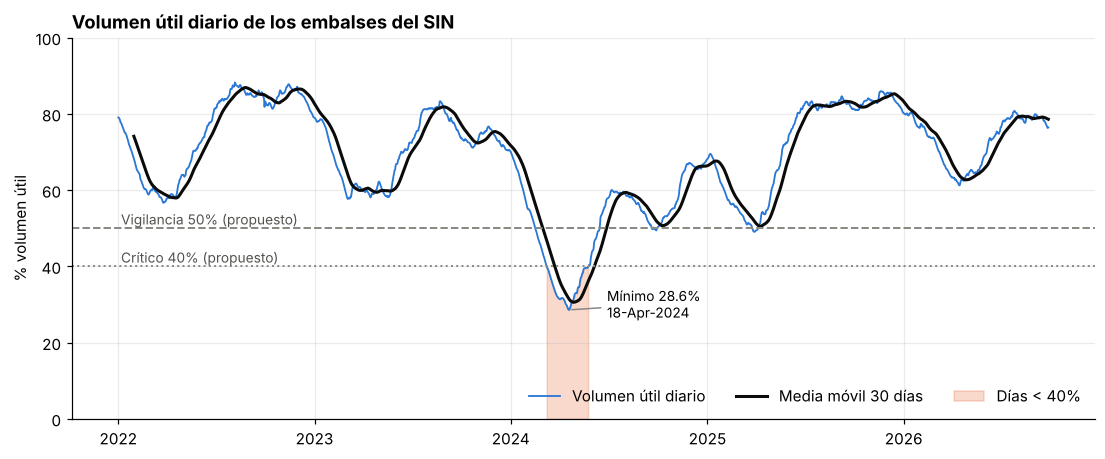

In [4]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(r.index, r, color=AZUL, lw=1.2, label="Volumen útil diario")
ax.plot(r.rolling(30).mean(), color="#0b0b0b", lw=2, label="Media móvil 30 días")
for u, est, txt in [(UMBRAL_VIGILANCIA, "--", "Vigilancia"), (UMBRAL_CRITICO, ":", "Crítico")]:
    ax.axhline(u, color=GRIS, ls=est, lw=1.3)
    ax.text(r.index[5], u + 1, f"{txt} {u}% (propuesto)", color="#52514e", fontsize=9)
ax.fill_between(r.index, 0, r, where=r < UMBRAL_CRITICO, color=NARANJA, alpha=.25, label=f"Días < {UMBRAL_CRITICO}%")
minimo = r.idxmin()
ax.annotate(f"Mínimo {r.min():.1f}%\n{minimo:%d-%b-%Y}", (minimo, r.min()), xytext=(25, -5),
            textcoords="offset points", fontsize=9, arrowprops=dict(arrowstyle="-", color=GRIS))
ax.set(ylim=(0, 100), ylabel="% volumen útil", title="Volumen útil diario de los embalses del SIN")
ax.legend(loc="lower right", frameon=False, ncol=3)
guardar(fig, "01_reservas_diario"); plt.show()

In [5]:
anual = r.groupby(r.index.year).agg(promedio="mean", minimo="min", maximo="max", fecha_minimo="idxmin")
anual["fecha_minimo"] = anual["fecha_minimo"].dt.date
anual["dias_<_vigilancia"] = (r < UMBRAL_VIGILANCIA).groupby(r.index.year).sum()
anual["dias_<_critico"] = (r < UMBRAL_CRITICO).groupby(r.index.year).sum()
anual["var_prom_vs_año_ant_pp"] = anual["promedio"].diff()
anual.index.name = "año"
anual.round(1)

,promedio,minimo,maximo,fecha_minimo,dias_<_vigilancia,dias_<_critico,var_prom_vs_año_ant_pp
año,,,,,,,
2022,75.7,56.7,88.2,2022-03-26,0,0,NaN
2023,70.8,57.7,83.3,2023-03-04,0,0,-4.9
2024,51.8,28.6,70.1,2024-04-18,129,78,-19.0
2025,72.8,49.1,86.0,2025-03-29,11,0,21.0
2026,73.2,61.2,80.8,2026-04-15,0,0,0.4


> 2026 es un año parcial (hasta el 27-sep), así que sus promedios no son comparables con un año completo.

### 3.2 Estacionalidad: ¿en qué meses es más vulnerable el sistema?

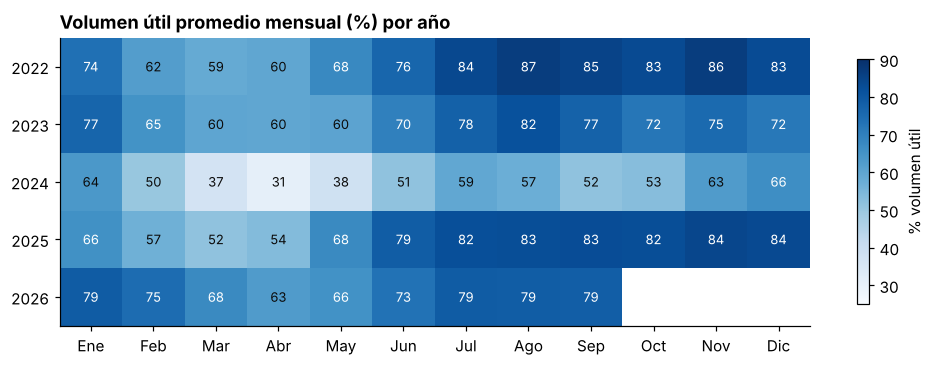

,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
mean,71.8,61.9,54.9,53.3,59.9,69.9,76.4,77.4,75.1,72.8,77.2,76.2
min,63.7,50.2,36.8,30.7,38.1,51.5,59.3,57.3,51.6,53.1,62.6,66.4
max,78.9,75.0,67.5,62.8,67.7,78.6,83.9,86.7,85.0,83.2,86.5,83.5


In [6]:
mensual_r = r.resample("MS").mean()
tabla = mensual_r.groupby([mensual_r.index.year, mensual_r.index.month]).first().unstack()
meses = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]

fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(tabla.values, cmap="Blues", vmin=25, vmax=90, aspect="auto")
ax.set_xticks(range(12), meses); ax.set_yticks(range(len(tabla)), tabla.index); ax.grid(False)
for i in range(tabla.shape[0]):
    for j in range(12):
        v = tabla.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5, color="white" if v > 64 else "#0b0b0b")
fig.colorbar(im, ax=ax, label="% volumen útil", shrink=.85)
ax.set_title("Volumen útil promedio mensual (%) por año")
guardar(fig, "02_reservas_heatmap"); plt.show()

perfil_mes = mensual_r.groupby(mensual_r.index.month).agg(["mean", "min", "max"]).set_axis(meses)
perfil_mes.round(1).T

### 3.3 Velocidad de cambio: caídas y recuperaciones a 30 días

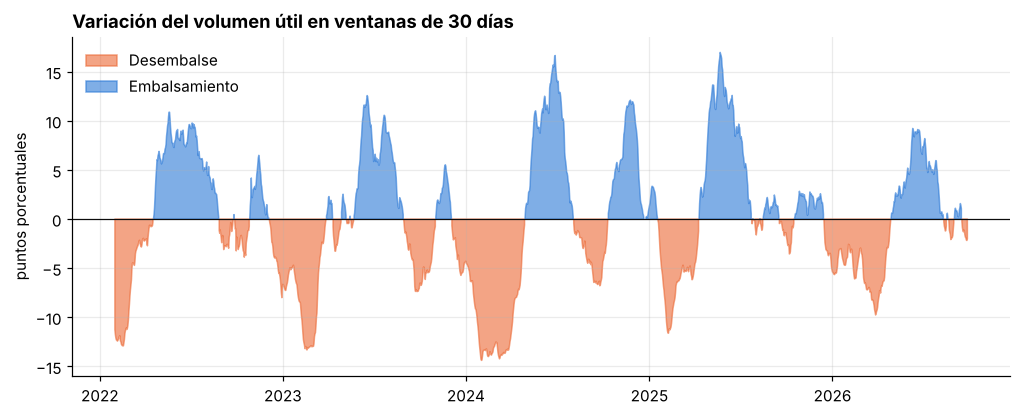

Top 5 caídas a 30 días (una por mes):
fecha
2024-02   -14.4
2024-01   -14.3
2024-03   -14.2
2023-02   -13.3
2023-03   -13.0
Freq: M

Mayor recuperación: +17.0 pp al 22-May-2025


In [7]:
d30 = r.diff(30).rename("var_30d_pp")
fig, ax = plt.subplots()
ax.fill_between(d30.index, 0, d30, where=d30 < 0, color=NARANJA, alpha=.6, label="Desembalse")
ax.fill_between(d30.index, 0, d30, where=d30 >= 0, color=AZUL, alpha=.6, label="Embalsamiento")
ax.axhline(0, color="#0b0b0b", lw=.8)
ax.set(ylabel="puntos porcentuales", title="Variación del volumen útil en ventanas de 30 días")
ax.legend(frameon=False, loc="upper left"); guardar(fig, "03_variacion_30d"); plt.show()

print("Top 5 caídas a 30 días (una por mes):")
caidas = d30.groupby(d30.index.to_period("M")).min().nsmallest(5)
print(caidas.round(1).to_string())
print(f"\nMayor recuperación: +{d30.max():.1f} pp al {d30.idxmax():%d-%b-%Y}")

### 3.4 Distribución y justificación de los umbrales propuestos

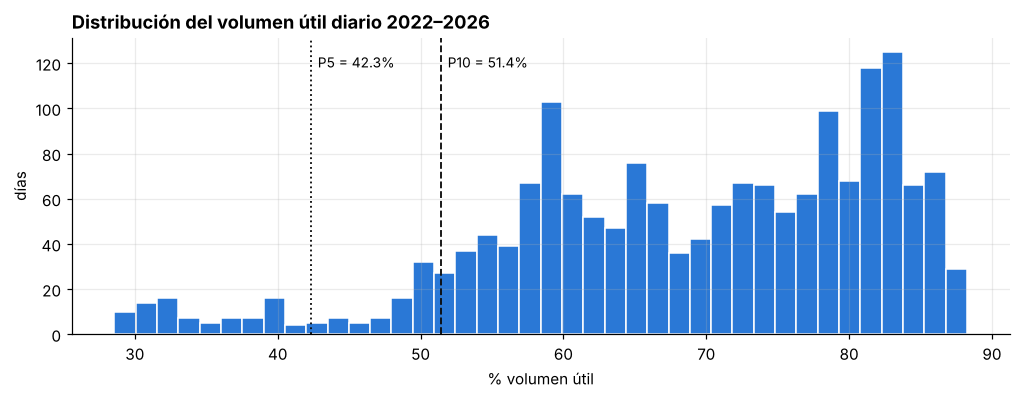

count    1731.00
mean       68.59
std        13.40
min        28.57
25%        59.32
50%        70.59
75%        80.21
max        88.25


In [8]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.hist(r, bins=40, color=AZUL, edgecolor="white")
for q, est in [(.05, ":"), (.10, "--")]:
    ax.axvline(r.quantile(q), color="#0b0b0b", ls=est, lw=1.2)
    ax.text(r.quantile(q) + .5, ax.get_ylim()[1] * .9, f"P{int(q*100)} = {r.quantile(q):.1f}%", fontsize=9)
ax.set(xlabel="% volumen útil", ylabel="días", title="Distribución del volumen útil diario 2022–2026")
guardar(fig, "04_distribucion"); plt.show()
print(r.describe().round(2).to_string())

**Justificación de los umbrales:** el umbral de *vigilancia* (50 %) queda muy cerca del percentil 10 de la serie, es decir, de un nivel que solo se ve en el 10 % de los días más secos. El umbral *crítico* (40 %) solo se cruzó durante El Niño 2023-24. Ambos son **propuestas del analista**: según la RACI, el **Data Owner** los aprueba (actividad "Definir umbrales de alerta de riesgo").

## 4. Aportes hídricos vs. media histórica (P2, P3)
Los aportes miden cuánta agua llega a los embalses. Si están por debajo del 100 % de la media histórica, el año es más seco de lo normal.

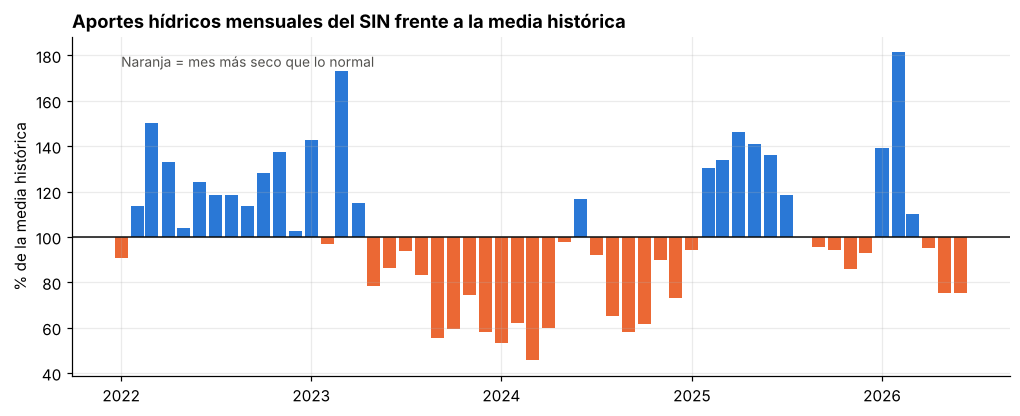

Racha seca más larga: 13 meses (May-2023 a May-2024), promedio 70% de la media


In [9]:
a = ds["aportes"]
ap = a.groupby("fecha")[["aportes_energia_kwh", "aportes_media_historica_energia_kwh"]].sum(min_count=1)
ap["aportes_pct_media"] = 100 * ap["aportes_energia_kwh"] / ap["aportes_media_historica_energia_kwh"]

fig, ax = plt.subplots()
colores = np.where(ap["aportes_pct_media"] < 100, NARANJA, AZUL)
ax.bar(ap.index, ap["aportes_pct_media"] - 100, bottom=100, width=25, color=colores)
ax.axhline(100, color="#0b0b0b", lw=1)
ax.set(ylabel="% de la media histórica", title="Aportes hídricos mensuales del SIN frente a la media histórica")
ax.text(ap.index[0], 175, "Naranja = mes más seco que lo normal", fontsize=9, color="#52514e")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
guardar(fig, "05_aportes_vs_media"); plt.show()

seco = ap["aportes_pct_media"] < 100
racha = (seco != seco.shift()).cumsum()
mayor = seco.groupby(racha).sum().idxmax()
tramo = ap[racha == mayor]
print(f"Racha seca más larga: {len(tramo)} meses ({tramo.index.min():%b-%Y} a {tramo.index.max():%b-%Y}), "
      f"promedio {tramo['aportes_pct_media'].mean():.0f}% de la media")

### 4.1 ¿Los aportes anticipan la variación de las reservas?

Correlación (Pearson) aportes %media → variación mensual de reservas:
rezago 0 mes(es)    0.15
rezago 1 mes(es)    0.13
rezago 2 mes(es)    0.10
rezago 3 mes(es)    0.19

Correlación aportes promedio 6 meses vs. nivel de reservas: 0.63


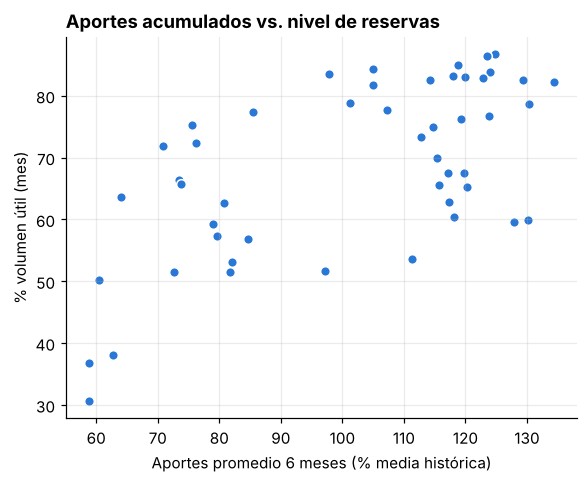

In [10]:
mens = pd.DataFrame({"reservas_pct": mensual_r, "aportes_pct_media": ap["aportes_pct_media"]})
mens["var_reservas_pp"] = mens["reservas_pct"].diff()
rezagos = {f"rezago {k} mes(es)": mens["var_reservas_pp"].corr(mens["aportes_pct_media"].shift(k)) for k in range(4)}
print("Correlación (Pearson) aportes %media → variación mensual de reservas:")
print(pd.Series(rezagos).round(2).to_string())

# Aportes acumulados de 6 meses vs. nivel de reservas
mens["aportes_6m"] = mens["aportes_pct_media"].rolling(6).mean()
print(f"\nCorrelación aportes promedio 6 meses vs. nivel de reservas: {mens['aportes_6m'].corr(mens['reservas_pct']):.2f}")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(mens["aportes_6m"], mens["reservas_pct"], color=AZUL, s=40, edgecolor="white")
ax.set(xlabel="Aportes promedio 6 meses (% media histórica)", ylabel="% volumen útil (mes)",
       title="Aportes acumulados vs. nivel de reservas")
guardar(fig, "06_aportes_vs_reservas"); plt.show()

## 5. Generación por tecnología: ¿cómo responde el sistema a embalses bajos? (P5)

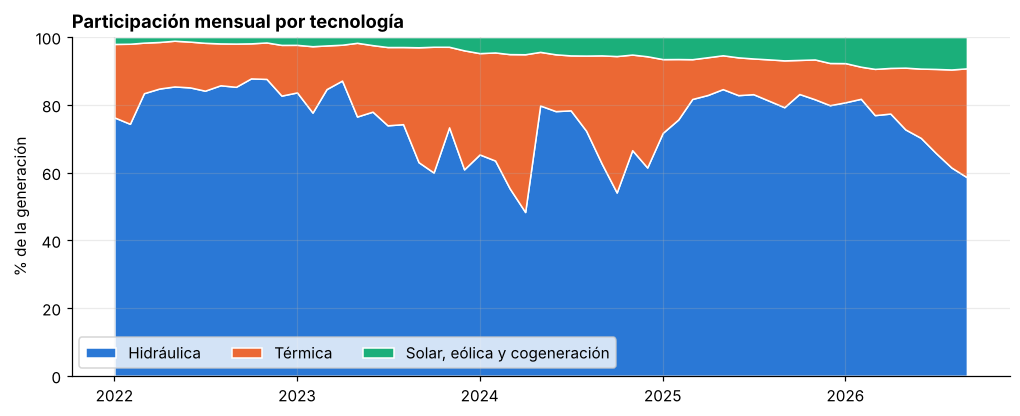

Correlación reservas vs. participación térmica: -0.42
tipo_generacion  HIDRAULICA  TERMICA  OTRAS
año                                        
2022                   83.6     14.7    1.7
2023                   74.4     22.9    2.7
2024                   65.5     29.4    5.1
2025                   80.6     12.9    6.5
2026                   71.7     19.2    9.1


In [11]:
g = ds["generacion"]
g_dia = (g.assign(kwh=g[HORAS].sum(axis=1)).groupby(["fecha", "tipo_generacion"])["kwh"].sum().unstack(fill_value=0))
g_mes = g_dia.resample("MS").sum()
part = g_mes.div(g_mes.sum(axis=1), axis=0) * 100
part["OTRAS"] = part.drop(columns=["HIDRAULICA", "TERMICA"]).sum(axis=1)
part = part[["HIDRAULICA", "TERMICA", "OTRAS"]]

fig, ax = plt.subplots()
ax.stackplot(part.index, part.T, colors=[AZUL, NARANJA, AGUA], labels=["Hidráulica", "Térmica", "Solar, eólica y cogeneración"],
             edgecolor="white", linewidth=1)
ax.set(ylim=(0, 100), ylabel="% de la generación", title="Participación mensual por tecnología")
ax.legend(loc="lower left", frameon=True, ncol=3)
guardar(fig, "07_mix_generacion"); plt.show()

mens["termica_pct"] = part["TERMICA"]; mens["hidraulica_pct"] = part["HIDRAULICA"]; mens["otras_pct"] = part["OTRAS"]
print(f"Correlación reservas vs. participación térmica: {mens['reservas_pct'].corr(mens['termica_pct']):.2f}")
print(part.groupby(part.index.year).mean().round(1).rename_axis("año").to_string())

## 6. Demanda de energía del SIN (P5)

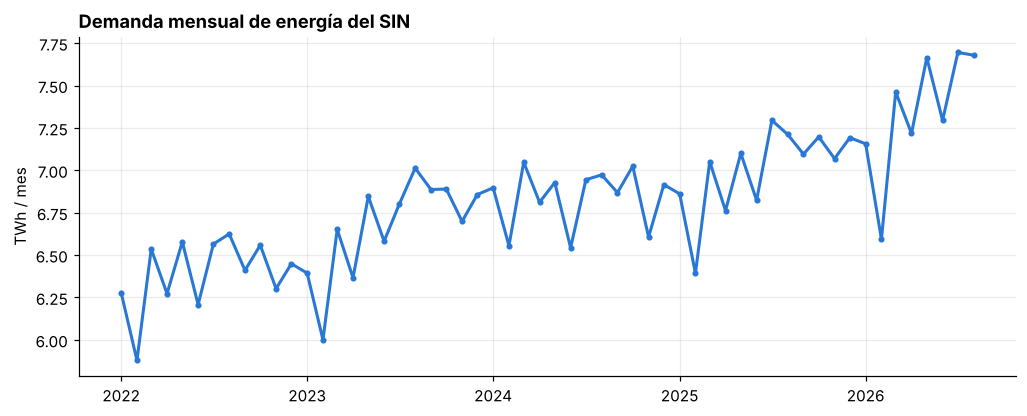

Demanda diaria promedio (GWh/día) y crecimiento anual:
       GWh_dia  crec_%
fecha                 
2022     210.0     NaN
2023     219.1     4.3
2024     224.3     2.4
2025     230.3     2.6
2026     241.9     5.1

Demanda no atendida total: 313.9 GWh = 0.081% de la demanda


In [12]:
dm = ds["demanda"].set_index("fecha")
dm_mes = dm["demanda_energia_sin_kwh"].resample("MS").sum() / 1e9   # GWh -> TWh
fig, ax = plt.subplots()
ax.plot(dm_mes.index[:-1], dm_mes.iloc[:-1], color=AZUL, marker="o", ms=3)   # se excluye el mes en curso (incompleto)
ax.set(ylabel="TWh / mes", title="Demanda mensual de energía del SIN")
guardar(fig, "08_demanda"); plt.show()

dm_dia_anual = dm["demanda_energia_sin_kwh"].groupby(dm.index.year).mean() / 1e6
print("Demanda diaria promedio (GWh/día) y crecimiento anual:")
print(pd.DataFrame({"GWh_dia": dm_dia_anual.round(1), "crec_%": (dm_dia_anual.pct_change() * 100).round(1)}).to_string())
dna = dm["demanda_no_atendida_kwh"].fillna(0)
print(f"\nDemanda no atendida total: {dna.sum()/1e6:.1f} GWh = {100*dna.sum()/dm['demanda_energia_sin_kwh'].sum():.3f}% de la demanda")
mens["demanda_twh"] = dm_mes

## 7. Vertimientos: el otro extremo del riesgo (P4)

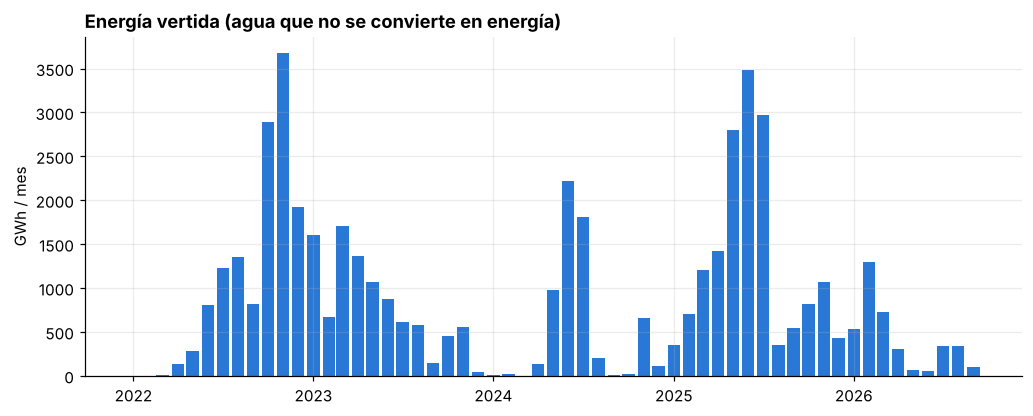

Correlación reservas vs. vertimientos: 0.27
Top embalses por energía vertida (GWh):
nombre_embalse
ITUANGO      29635.9
ESMERALDA     3993.2
GUAVIO        3222.2
TOPOCORO      2831.4
PLAYAS        1651.5


In [13]:
v = ds["vertimientos"]
v_mes = v.groupby(pd.Grouper(key="fecha", freq="MS"))["vertimientos_energia_kwh"].sum() / 1e6   # GWh
mens["vertimientos_gwh"] = v_mes.reindex(mens.index).fillna(0)
fig, ax = plt.subplots()
ax.bar(v_mes.index, v_mes, width=25, color=AZUL)
ax.set(ylabel="GWh / mes", title="Energía vertida (agua que no se convierte en energía)")
guardar(fig, "09_vertimientos"); plt.show()
print(f"Correlación reservas vs. vertimientos: {mens['reservas_pct'].corr(mens['vertimientos_gwh']):.2f}")
print("Top embalses por energía vertida (GWh):")
print((v.groupby("nombre_embalse")["vertimientos_energia_kwh"].sum() / 1e6).nlargest(5).round(1).to_string())

## 8. Compras en bolsa nacional (P4)
> ⚠️ Este dataset contiene **cantidades compradas (kWh) por agente**, no el **precio** de bolsa que menciona la Entrega 1 (§7). Aquí se usa solo como señal de volumen. El precio ($/kWh) debe descargarse aparte si se quiere el análisis económico.

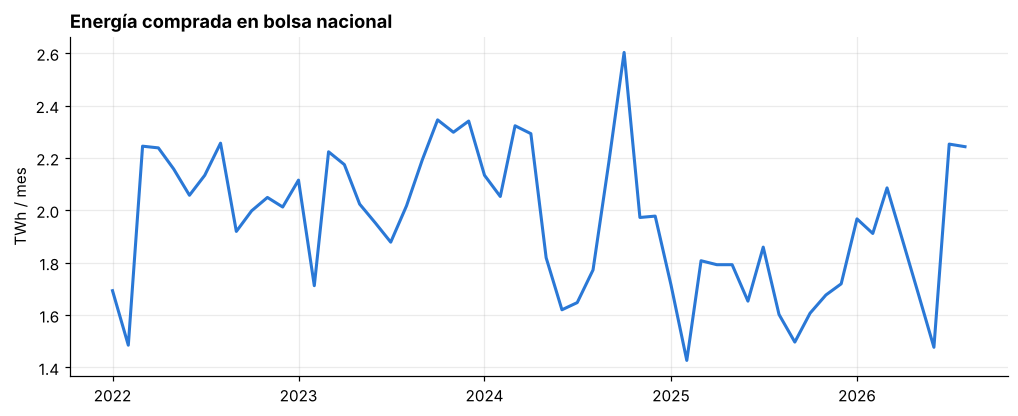

Filas antes/después de quedarse con la última versión: 199,213 / 199,213 (no había versiones repetidas)
Correlación reservas vs. compras en bolsa: -0.15


In [14]:
cb = ds["compras_bolsa"]
# Varias versiones de liquidación (TX1…TXF) por día: se usa la última disponible por fecha y agente
orden = {v: i for i, v in enumerate(sorted(cb["version"].unique(), key=lambda s: (s == "TXF", s)))}
cb_u = (cb.assign(o=cb["version"].map(orden)).sort_values("o")
          .drop_duplicates(["fecha", "codigo_agente"], keep="last"))
cb_mes = (cb_u[HORAS].sum(axis=1).groupby(cb_u["fecha"]).sum()).resample("MS").sum() / 1e9
mens["compras_bolsa_twh"] = cb_mes
fig, ax = plt.subplots()
ax.plot(cb_mes.index[:-1], cb_mes.iloc[:-1], color=AZUL)
ax.set(ylabel="TWh / mes", title="Energía comprada en bolsa nacional")
guardar(fig, "10_compras_bolsa"); plt.show()
print(f"Filas antes/después de quedarse con la última versión: {len(cb):,} / {len(cb_u):,} (no había versiones repetidas)")
print(f"Correlación reservas vs. compras en bolsa: {mens['reservas_pct'].corr(mens['compras_bolsa_twh']):.2f}")

## 9. Matriz de correlación mensual y tabla para el dashboard

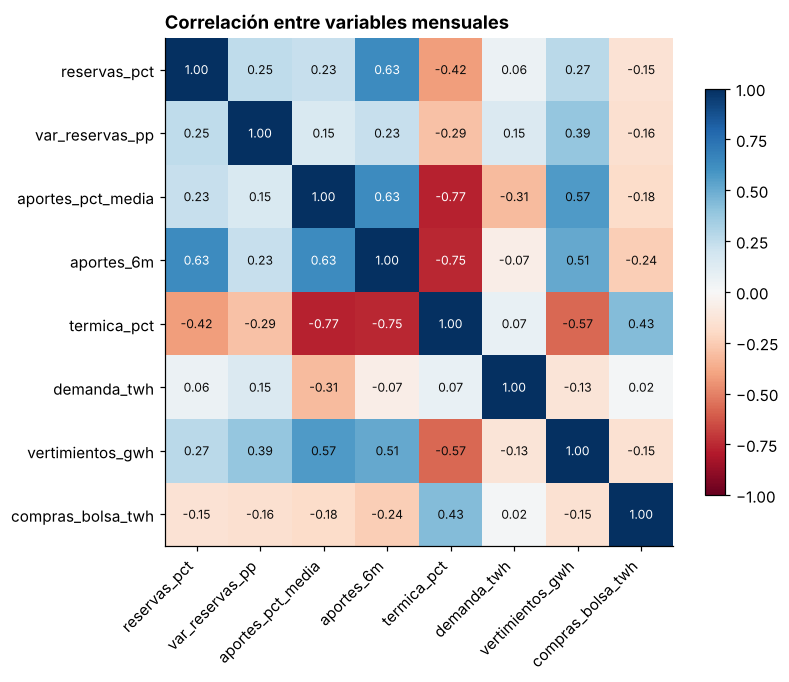

In [15]:
cols = ["reservas_pct", "var_reservas_pp", "aportes_pct_media", "aportes_6m", "termica_pct",
        "demanda_twh", "vertimientos_gwh", "compras_bolsa_twh"]
corr = mens[cols].corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right"); ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iat[i, j]) > .6 else "#0b0b0b")
fig.colorbar(im, ax=ax, shrink=.8); ax.set_title("Correlación entre variables mensuales")
guardar(fig, "11_correlacion"); plt.show()

In [16]:
# Salida del EDA → insumo del dashboard (Entrega 3). El mes en curso se marca como incompleto.
mens["mes_completo"] = mens.index < pd.Timestamp(r.index.max()).to_period("M").to_timestamp()
mens["en_vigilancia"] = mens["reservas_pct"] < UMBRAL_VIGILANCIA
mens.index.name = "mes"
mens.to_parquet(OUT_DIR / "eda_mensual.parquet")
print(f"Guardado {OUT_DIR / 'eda_mensual.parquet'}: {mens.shape}")
mens.tail(4).round(1)

Guardado /home/claude/dataofficestrategy_proyectofinal/data/processed/eda/eda_mensual.parquet: (57, 12)


,reservas_pct,aportes_pct_media,var_reservas_pp,aportes_6m,termica_pct,hidraulica_pct,otras_pct,demanda_twh,vertimientos_gwh,compras_bolsa_twh,mes_completo,en_vigilancia
mes,,,,,,,,,,,,
2026-06-01,73.3,75.3,7.7,112.8,20.5,70.2,9.3,7.3,60.4,1.5,True,False
2026-07-01,79.0,NaN,5.7,NaN,24.8,65.8,9.4,7.7,338.2,2.3,True,False
2026-08-01,78.8,NaN,-0.2,NaN,28.9,61.5,9.6,7.7,344.2,2.2,True,False
2026-09-01,78.6,NaN,-0.2,NaN,32.2,58.6,9.2,6.3,95.8,1.7,False,False


## 10. Salida para la alerta automática (M5 · Power Automate)
Se genera `automatizacion/reservas_alerta.xlsx` con una **Tabla de Excel** llamada `TablaReservas`. Es el formato que exige la acción *Enumerar filas presentes en una tabla*. El flujo solo lee la columna `estado` de la fecha más reciente; los umbrales se mantienen en este notebook.

In [17]:
from openpyxl import load_workbook
from openpyxl.worksheet.table import Table, TableStyleInfo

alerta = pd.DataFrame({
    "fecha": r.index.strftime("%Y-%m-%d"),            # texto ISO: Power Automate lo compara sin líos
    "volumen_util_diario_pct": r.round(2).values,
    "var_30d_pp": r.diff(30).round(2).values,
    "umbral_vigilancia": UMBRAL_VIGILANCIA,
    "umbral_critico": UMBRAL_CRITICO,
})
alerta["estado"] = np.select(
    [alerta.volumen_util_diario_pct < UMBRAL_CRITICO, alerta.volumen_util_diario_pct < UMBRAL_VIGILANCIA],
    ["CRITICO", "VIGILANCIA"], default="NORMAL")

ruta = RAIZ / "automatizacion" / "reservas_alerta.xlsx"
ruta.parent.mkdir(exist_ok=True)
alerta.to_excel(ruta, index=False, sheet_name="Reservas")
wb = load_workbook(ruta); ws = wb["Reservas"]
tabla = Table(displayName="TablaReservas", ref=ws.dimensions)
tabla.tableStyleInfo = TableStyleInfo(name="TableStyleMedium2", showRowStripes=True)
ws.add_table(tabla); wb.save(ruta)
print(f"Guardado {ruta.relative_to(RAIZ)}: {len(alerta)} filas")
print(alerta["estado"].value_counts().to_string())
alerta.tail(3)

Guardado automatizacion/reservas_alerta.xlsx: 1731 filas
estado
NORMAL        1591
CRITICO         78
VIGILANCIA      62


,fecha,volumen_util_diario_pct,var_30d_pp,umbral_vigilancia,umbral_critico,estado
1728,2026-09-25,76.56,-2.13,50,40,NORMAL
1729,2026-09-26,76.29,-2.18,50,40,NORMAL
1730,2026-09-27,76.44,-2.00,50,40,NORMAL


## 11. Hallazgos e implicaciones para la decisión

**H1 · El riesgo es episódico y coincide con el periodo seco 2023-24, no con una tendencia (P1).** El volumen útil promedió entre 71 y 76 % en 2022, 2023, 2025 y 2026 (parcial), pero cayó a **52 % en 2024**, con un mínimo de **28,6 % el 18-abr-2024**. Es el único año con días bajo el 40 % (78 días) y bajo el 30 % (9 días). En 2025 el sistema se recuperó por completo (+17,0 pp en 30 días hacia mayo).
→ *Implicación:* un monitoreo que solo mire el promedio anual no detecta el riesgo. Hacen falta alertas **diarias** (O1, O2).

**H2 · La vulnerabilidad tiene calendario (P1, P3).** Marzo y abril son los meses más bajos (≈ 53–55 % en promedio). Julio, agosto y noviembre son los más altos (≈ 76–77 %). Las mayores caídas a 30 días se concentran entre enero y marzo.
→ *Implicación:* el Comité de riesgo debería revisar con más frecuencia entre **diciembre y abril**, y el umbral podría ajustarse según el mes (Fase 2).

**H3 · Lo que anticipa el riesgo es el déficit acumulado de aportes, no el de un solo mes (P2, P3).** La racha seca más larga duró **13 meses consecutivos (may-2023 a may-2024)**: promedió 70 % de la media y tocó 46 % en mar-2024, justo antes del mínimo de reservas. Mes a mes, la correlación entre aportes y variación de reservas es débil (0,10–0,19 con rezagos de 0 a 3 meses). En cambio, el **promedio de aportes de 6 meses** sí acompaña el nivel de reservas (r = 0,63).
→ *Implicación:* la alerta M5 podría sumar una **condición anticipada** basada en aportes acumulados (p. ej., promedio de 6 meses < 80 % de la media). El valor exacto lo define el Data Owner; con 57 meses de historia es una hipótesis para la Fase 2, no un modelo validado.

**H4 · Con embalses bajos el sistema compensa con térmica (P4, P5).** La participación térmica pasó de 14,7 % (2022) a **29,4 % en 2024** y bajó a 12,9 % en 2025; su correlación con las reservas es **moderada y negativa (r = −0,42)**. Para vigilar: en ago-sep 2026 la térmica volvió a 29–32 % aunque las reservas están cerca del 79 %. Los vertimientos casi no se relacionan con las reservas del SIN (r = 0,27) porque **Ituango concentra la mayor parte** (≈ 29,6 TWh), algo propio de esa central y no de la hidrología del sistema.
→ *Implicación:* el dashboard debería mostrar la participación térmica junto a las reservas. Los vertimientos conviene presentarlos **por embalse**, no como indicador agregado.

**H5 · Los datos son aptos para decidir (P6).** `reservas` está 100 % completa, sin duplicados ni valores inválidos, y la generación cuadra exactamente entre dos fuentes de XM. Los nulos de `aportes` están marcados como *dato no registrado* por la fuente.
→ *Implicación:* la meta O3 (≥ 98 % de registros válidos) es alcanzable. Las reglas de calidad del Plan de Gobierno pueden partir de este perfil.

**Limitaciones:** P4 y P5 quedan parciales (no hay precio de bolsa ni capacidad efectiva). 2026 es parcial (el crecimiento de demanda de 5,1 % compara ene–sep con años completos) (aportes hasta jun-2026; el resto hasta sep-2026). `compras_bolsa` es volumen y no precio. Las correlaciones no implican causalidad. Los umbrales están pendientes de aprobación del Data Owner.